# EDA текстов Twitter

Анализ выгрузки `twitter-dump-03-11-2026.csv` для исследования прогнозирования Bitcoin. Одна строка соответствует сохранённому твиту. Изучаем качество данных, покрытие по времени и аккаунтам, тексты, активность и упоминания рыночных тем.

CSV должен лежать рядом с ноутбуком. Для запуска нужны pandas, numpy, matplotlib и scikit-learn. Все даты и часы указаны в UTC. Анализ описывает содержимое выгрузки, её полноту относительно Twitter по одному CSV установить нельзя.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.feature_extraction.text import CountVectorizer

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (10, 4), 'figure.dpi': 110})
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 30)

## 1. Загрузка и структура

ID читаем как строки, чтобы сохранить все цифры. Поле raw с исходным JSON пропускаем при загрузке. Поля публикации, текста, автора и счётчиков доступны в отдельных столбцах. created_at обозначает время публикации, received_at — время сохранения выгрузки.

In [2]:
id_columns = ['tweet_id', 'author_id', 'in_reply_to_id', 'conversation_id',
              'quoted_tweet_id', 'retweeted_tweet_id']
df = pd.read_csv('twitter-dump-03-11-2026.csv', usecols=lambda column: column != 'raw',
                 dtype=dict.fromkeys(id_columns, 'string'))
for column in ['created_at', 'received_at']:
    df[column] = pd.to_datetime(df[column], utc=True, format='mixed', errors='coerce')

print(f'Выгрузка: {len(df):,} строк, {df.shape[1]} загруженный столбец')
display(df[['tweet_id', 'account', 'created_at', 'text', 'lang', 'received_at']].head())
display(df.dtypes.astype(str).to_frame('Тип после загрузки'))

Выгрузка: 200,621 строк, 21 загруженный столбец


,tweet_id,account,created_at,text,lang,received_at
0,1455913552942977033,bitcoinmagazine,2021-11-03 15:03:35+00:00,#Bitcoin becoming preferred payment for gas purchases – Major El Salvador newspaper https://t.co...,en,2026-11-02 20:20:52.554807+00:00
1,1455914770788278279,wublockchain,2021-11-03 15:08:25+00:00,Binance OKEx and others have announced that they will launch the Polkadot slot auction warm-up a...,en,2026-11-02 20:42:40.525944+00:00
2,1455916126161063936,jseyff,2021-11-03 15:13:48+00:00,RT @BitcoinMagazine: You can buy a fraction of a #Bitcoin https://t.co/CDav1kltyE,en,2026-11-02 17:40:20.568778+00:00
3,1455924410121179136,binance,2021-11-03 15:46:43+00:00,Join us on November 9 at 4PM UTC to learn about NFTs in the charity and digital art space!\n\nFe...,en,2026-11-02 20:14:30.586954+00:00
4,1455928344273461252,tier10k,2021-11-03 16:02:21+00:00,NYC Mayor-elect Eric Adams Aims to Make NYC Crypto-Friendly With Coin Similar to Miami's - Bloom...,en,2026-11-02 17:26:39.155467+00:00


,Тип после загрузки
tweet_id,string
account,object
author_id,string
author_username,object
author_name,object
created_at,"datetime64[ns, UTC]"
text,object
lang,object
url,object
is_reply,int64


## 2. Пропуски, даты и дубли

Пустые строки учитываем вместе с пропусками. Отсутствующие ID цитаты или ретвита допустимы для обычного твита. Повторы по tweet_id считаем отдельно от одинаковых текстов. В таблице дублей число означает количество повторных строк сверх первой.

In [3]:
missing = df.replace(r'^\s*$', pd.NA, regex=True).isna().sum().to_frame('Пропусков')
missing['Доля, %'] = 100 * missing['Пропусков'] / len(df)
display(missing.round(2))

exact_text = df['text'].str.lower().str.replace(r'\s+', ' ', regex=True).str.strip()
display(pd.Series({
    'Полные повторы загруженных строк': df.duplicated().sum(),
    'Повторные tweet_id': df['tweet_id'].duplicated().sum(),
    'Повторные URL твитов': df['url'].duplicated().sum(),
    'Повторные тексты без учёта регистра и пробелов': exact_text.duplicated().sum(),
    'Пустой текст': df['text'].fillna('').str.strip().eq('').sum(),
    'Нераспознанная дата публикации': df['created_at'].isna().sum(),
    'Нераспознанная дата сохранения': df['received_at'].isna().sum(),
    'Публикация позже сохранения': df['created_at'].gt(df['received_at']).sum()
}).to_frame('Строк'))

tweets = df.drop_duplicates('tweet_id').dropna(subset=['created_at']).copy()
tweets['day'] = tweets['created_at'].dt.floor('D')
first, last = tweets['created_at'].min(), tweets['created_at'].max()
display(pd.Series({'Первый твит UTC': first, 'Последний твит UTC': last,
                   'Уникальных твитов': len(tweets), 'Аккаунтов': tweets['account'].nunique()}).to_frame('Значение'))

,Пропусков,"Доля, %"
tweet_id,0,0.00
account,0,0.00
author_id,0,0.00
author_username,0,0.00
author_name,0,0.00
created_at,0,0.00
text,0,0.00
lang,0,0.00
url,0,0.00
is_reply,0,0.00


,Строк
Полные повторы загруженных строк,0
Повторные tweet_id,0
Повторные URL твитов,0
Повторные тексты без учёта регистра и пробелов,2121
Пустой текст,0
Нераспознанная дата публикации,0
Нераспознанная дата сохранения,0
Публикация позже сохранения,0


,Значение
Первый твит UTC,2021-11-03 15:03:35+00:00
Последний твит UTC,2026-11-02 21:35:17+00:00
Уникальных твитов,200621
Аккаунтов,14


## 3. Покрытие по времени

Ноль на графике означает отсутствие записей в CSV. Первый и последний дни и месяцы архива могут быть неполными. На графиках сохраняем все дни и месяцы между первым и последним твитами.

Дней без записей между крайними датами: 0


,Твитов в день
count,1824.0
mean,109.9
std,46.0
min,21.0
10%,45.0
50%,118.0
90%,164.0
99%,216.0
max,301.0


,Твитов
created_at,
2022-12-13 00:00:00+00:00,301
2022-01-26 00:00:00+00:00,281
2022-11-10 00:00:00+00:00,261
2021-11-26 00:00:00+00:00,249
2021-12-06 00:00:00+00:00,243


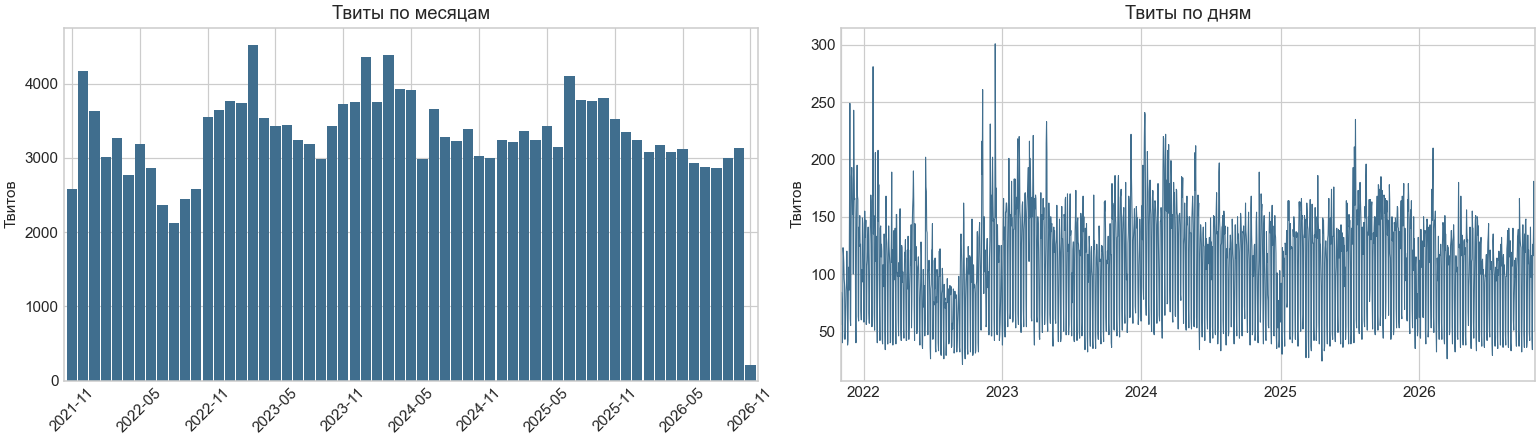

In [4]:
daily = tweets.set_index('created_at').resample('D').size()
monthly = daily.resample('MS').sum()
display(daily.iloc[1:-1].describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(1).to_frame('Твитов в день'))
print(f'Дней без записей между крайними датами: {daily.eq(0).sum()}')
display(daily.nlargest(5).rename('Твитов').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout='constrained')
monthly.set_axis(monthly.index.strftime('%Y-%m')).plot.bar(ax=axes[0], color='#406e8e', width=0.9)
axes[0].set_xticks(range(0, len(monthly), 6), monthly.index.strftime('%Y-%m')[::6], rotation=45)
axes[0].set(title='Твиты по месяцам', xlabel='', ylabel='Твитов')
daily.plot(ax=axes[1], color='#406e8e', linewidth=0.7)
axes[1].set(title='Твиты по дням', xlabel='', ylabel='Твитов')
plt.show()

## 4. Аккаунты и неравномерность истории

Сравниваем вклад аккаунтов, даты их покрытия и число дней с публикациями. Максимальная пауза измеряет промежуток между двумя соседними записями одного аккаунта. Она не учитывает отрезки до его первого твита и после последнего. Пропуски на тепловой карте могут объясняться активностью автора и особенностями сбора.

Доля двух крупнейших аккаунтов: 40.9%


,Твитов,Первый UTC,Последний UTC,Дней с твитами,"Доля, %","Макс. пауза, дней"
account,,,,,,
whale_alert,43020,2021-11-24 22:20:33+00:00,2026-11-02 21:11:25+00:00,1794,21.44,2.17
coindesk,39118,2022-11-29 02:38:59+00:00,2026-11-02 21:27:27+00:00,1411,19.50,2.72
wublockchain,25448,2021-11-03 15:08:25+00:00,2026-11-02 16:03:54+00:00,1826,12.68,1.07
binance,21113,2021-11-03 15:46:43+00:00,2026-11-02 14:35:23+00:00,1821,10.52,2.92
bitcoinmagazine,20702,2021-11-03 15:03:35+00:00,2026-11-02 21:04:14+00:00,1825,10.32,1.14
lookonchain,10221,2021-12-22 06:01:29+00:00,2026-11-02 15:40:07+00:00,1611,5.09,39.99
ericbalchunas,10193,2021-11-03 17:38:53+00:00,2026-11-02 16:42:34+00:00,1727,5.08,10.52
jseyff,7303,2021-11-03 15:13:48+00:00,2026-11-02 21:04:48+00:00,1436,3.64,7.60
tier10k,5160,2021-11-03 16:02:21+00:00,2026-03-10 19:21:01+00:00,626,2.57,62.08


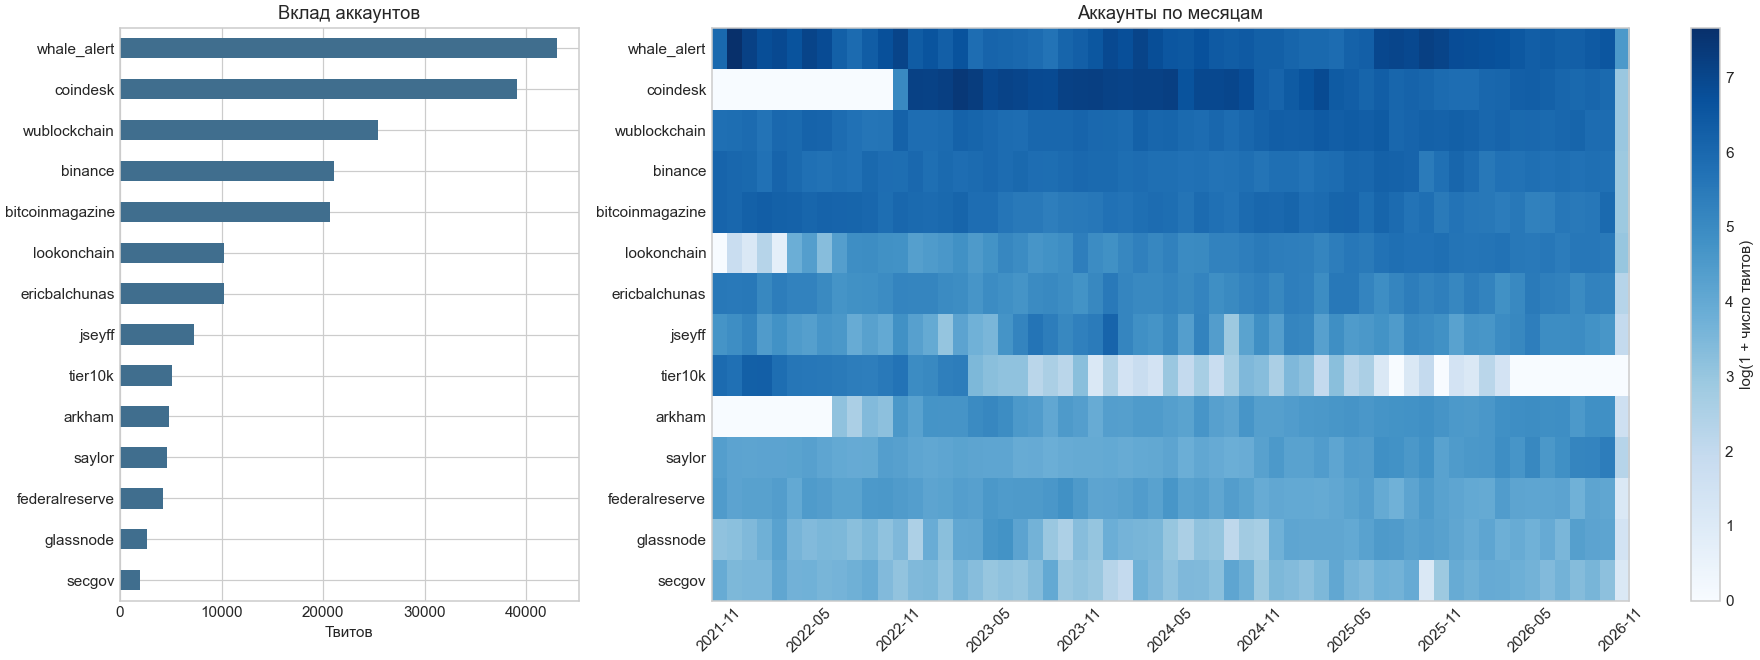

In [5]:
accounts = tweets.groupby('account').agg(
    tweets=('tweet_id', 'size'), first=('created_at', 'min'), last=('created_at', 'max'),
    days=('day', 'nunique')
).sort_values('tweets', ascending=False)
accounts['share_pct'] = 100 * accounts['tweets'] / len(tweets)
account_gap = tweets.sort_values(['account', 'created_at']).groupby('account')['created_at'].diff()
accounts['max_gap_days'] = account_gap.dt.total_seconds().groupby(tweets['account']).max() / 86400
display(accounts.rename(columns={'tweets': 'Твитов', 'first': 'Первый UTC', 'last': 'Последний UTC',
                                 'days': 'Дней с твитами', 'share_pct': 'Доля, %',
                                 'max_gap_days': 'Макс. пауза, дней'}).round(2))
print(f'Доля двух крупнейших аккаунтов: {accounts["share_pct"].head(2).sum():.1f}%')

account_month = pd.crosstab(tweets['account'], tweets['created_at'].dt.strftime('%Y-%m'))
account_month = account_month.reindex(index=accounts.index, columns=monthly.index.strftime('%Y-%m'), fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1, 2]}, layout='constrained')
accounts['tweets'].sort_values().plot.barh(ax=axes[0], color='#406e8e')
axes[0].set(title='Вклад аккаунтов', xlabel='Твитов', ylabel='')
image = axes[1].imshow(np.log1p(account_month), aspect='auto', cmap='Blues')
axes[1].set_yticks(range(len(accounts)), accounts.index)
axes[1].set_xticks(range(0, len(monthly), 6), monthly.index.strftime('%Y-%m')[::6], rotation=45)
axes[1].set(title='Аккаунты по месяцам')
axes[1].grid(False)
fig.colorbar(image, ax=axes[1], label='log(1 + число твитов)')
plt.show()

## 5. Языки, ретвиты, цитаты и ответы

Язык используем из поля lang. Ретвит определяем по retweeted_tweet_id, цитату — по quoted_tweet_id, ответ — по is_reply. В таблице флагов возможны пересечения. На графике типов цитатам даём приоритет над обычными публикациями, ретвитам над цитатами, ответам над ретвитами. retweet_count показывает число репостов сообщения и отличается от признака того, что сама строка является ретвитом.

Расхождений ретвит-ID и префикса RT: 0
Строк с ID родительского твита: 0
Несовпадений account и author_username: 0


,Твитов,"Доля, %"
lang,,
en,197166,98.28
zxx,849,0.42
sv,396,0.20
und,373,0.19
qme,277,0.14
qst,184,0.09
art,156,0.08
es,152,0.08
cs,121,0.06


,Твитов,"Доля, %"
is_retweet,24687,12.31
is_quote,14589,7.27
reply_flag,0,0.00


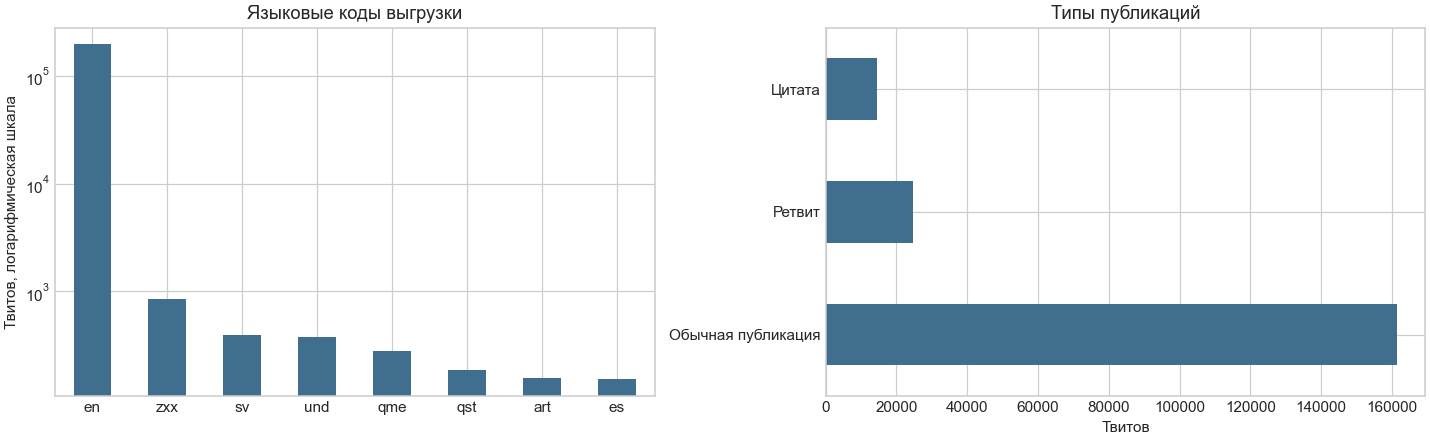

In [6]:
tweets['is_retweet'] = tweets['retweeted_tweet_id'].notna()
tweets['is_quote'] = tweets['quoted_tweet_id'].notna()
tweets['reply_flag'] = pd.to_numeric(tweets['is_reply'], errors='coerce').eq(1)
tweets['kind'] = 'Обычная публикация'
tweets.loc[tweets['is_quote'], 'kind'] = 'Цитата'
tweets.loc[tweets['is_retweet'], 'kind'] = 'Ретвит'
tweets.loc[tweets['reply_flag'], 'kind'] = 'Ответ'

languages = tweets['lang'].fillna('missing').value_counts().to_frame('Твитов')
languages['Доля, %'] = 100 * languages['Твитов'] / len(tweets)
display(languages.head(15).round(2))
flags = tweets[['is_retweet', 'is_quote', 'reply_flag']].sum().to_frame('Твитов')
flags['Доля, %'] = 100 * flags['Твитов'] / len(tweets)
display(flags.round(2))
print('Расхождений ретвит-ID и префикса RT:',
      tweets['is_retweet'].ne(tweets['text'].str.match(r'^RT\s+@', case=False, na=False)).sum())
print('Строк с ID родительского твита:', tweets['in_reply_to_id'].notna().sum())
print('Несовпадений account и author_username:',
      tweets['account'].str.lower().ne(tweets['author_username'].str.lower()).sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
languages['Твитов'].head(8).plot.bar(ax=axes[0], color='#406e8e', rot=0, logy=True)
axes[0].set(title='Языковые коды выгрузки', xlabel='', ylabel='Твитов, логарифмическая шкала')
tweets['kind'].value_counts().plot.barh(ax=axes[1], color='#406e8e')
axes[1].set(title='Типы публикаций', xlabel='Твитов', ylabel='')
plt.show()

## 6. Время суток и день недели

Показываем среднее число твитов на один календарный час соответствующего дня недели. Для знаменателя используем полные внутренние дни архива, включая часы без записей. Это характеристика собранной выборки с её меняющимся составом аккаунтов.

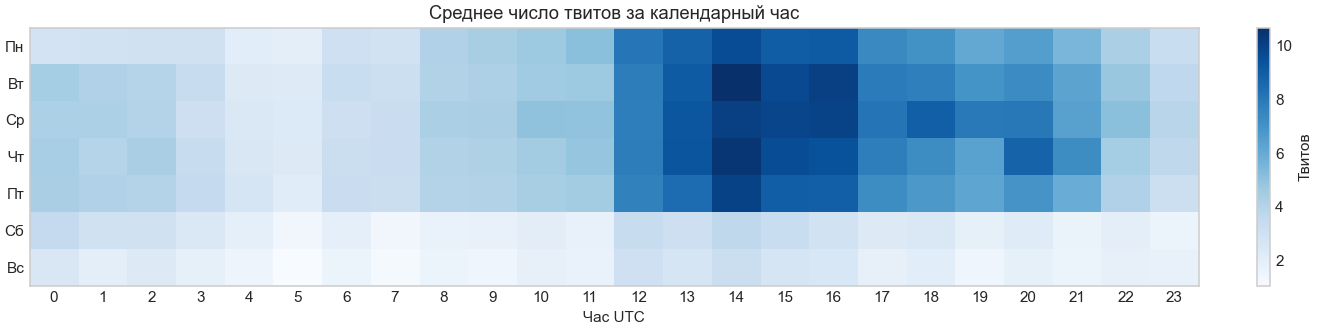

In [7]:
hour_grid = pd.date_range(first.normalize() + pd.Timedelta(days=1), last.normalize(),
                          freq='h', inclusive='left')
hourly_count = tweets.set_index('created_at').resample('h').size().reindex(hour_grid, fill_value=0)
activity = hourly_count.groupby([hourly_count.index.dayofweek, hourly_count.index.hour]).mean().unstack()
fig, ax = plt.subplots(figsize=(12, 3), layout='constrained')
image = ax.imshow(activity, aspect='auto', cmap='Blues')
ax.set_xticks(range(24), range(24))
ax.set_yticks(range(7), ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
ax.set(title='Среднее число твитов за календарный час', xlabel='Час UTC')
ax.grid(False)
fig.colorbar(image, ax=ax, label='Твитов')
plt.show()

## 7. Длина и структура текстов

Слова считаем разделением по пробелам. Это число отличается от числа токенов языковой модели. Отдельно измеряем длину после удаления ссылок. Окончание многоточием используем как повод для просмотра примеров, оно само по себе не доказывает обрезку.

,char_count,word_count,chars_without_urls
count,200621.0,200621.0,200621.0
mean,180.5,26.4,157.9
std,115.2,17.9,114.3
min,1.0,1.0,0.0
1%,23.0,3.0,12.0
50%,140.0,22.0,138.0
90%,301.0,47.0,277.0
99%,608.0,93.0,596.0
max,2873.0,413.0,2870.0


,"Доля твитов, %"
has_url,77.35
has_hashtag,40.94
has_mention,31.64
ends_ellipsis,9.74


,Твитов
Короче 20 символов после удаления ссылок,3883
Длиннее 280 символов,29686


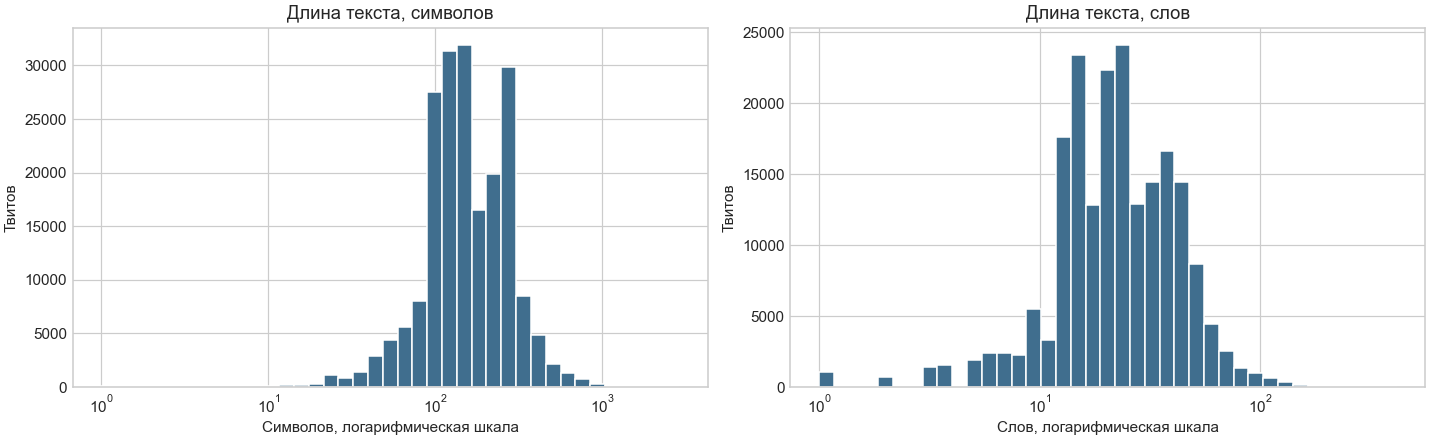

,account,created_at,char_count,text,url
187181,saylor,2026-06-15 16:27:53+00:00,2873,Bitcoin Capitalism — my keynote from @BTCPrague 2026.\n\nDigital Capital is the foundation for D...,https://x.com/saylor/status/2066558321394426082
51814,saylor,2023-03-14 22:19:37+00:00,2652,Why does the world need #Bitcoin?\n\nGPT-4: While it's a matter of perspective whether the world...,https://x.com/saylor/status/1635767667960209410
68322,coindesk,2023-08-03 15:40:23+00:00,2568,.@FTX_Official founder and former CEO Sam Bankman-Fried appeared in court last week as prosecut...,https://x.com/CoinDesk/status/1687126272562896896


,account,text,url
6,tier10k,Tinder owner Match is also looking to delve into metaverse through the recently bought Hyperconn...,https://x.com/tier10k/status/1455932969907105805
13,jseyff,RT @EricBalchunas: The Case of the Delayed Bitcoin Futures ETFs has been solved by ⁦@kgreifeld⁩....,https://x.com/JSeyff/status/1455953072086265856
36,jseyff,RT @EricBalchunas: Two congressman asking Genz to approve spot bitcoin ETF. Can’t understand why...,https://x.com/JSeyff/status/1455974065802448901


In [8]:
text = tweets['text'].fillna('')
text_without_urls = text.str.replace(r'https?://\S+', ' ', regex=True).str.replace(r'\s+', ' ', regex=True).str.strip()
tweets['char_count'] = text.str.len()
tweets['word_count'] = text.str.split().str.len()
tweets['chars_without_urls'] = text_without_urls.str.len()
tweets['has_url'] = text.str.contains(r'https?://', regex=True)
tweets['has_hashtag'] = text.str.contains(r'#\w+', regex=True)
tweets['has_mention'] = text.str.contains(r'@\w+', regex=True)
tweets['ends_ellipsis'] = text.str.contains(r'(?:…|\.\.\.)\s*$', regex=True)

display(tweets[['char_count', 'word_count', 'chars_without_urls']].describe(percentiles=[0.01, 0.5, 0.9, 0.99]).round(1))
structure = tweets[['has_url', 'has_hashtag', 'has_mention', 'ends_ellipsis']].mean().mul(100)
display(structure.to_frame('Доля твитов, %').round(2))
display(pd.Series({'Короче 20 символов после удаления ссылок': text_without_urls.str.len().lt(20).sum(),
                   'Длиннее 280 символов': text.str.len().gt(280).sum()}).to_frame('Твитов'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout='constrained')
for ax, column, label in zip(axes, ['char_count', 'word_count'], ['Символов', 'Слов']):
    tweets.loc[tweets[column] > 0, column].plot.hist(bins=np.geomspace(1, tweets[column].max() + 1, 40),
                                                   ax=ax, color='#406e8e', edgecolor='white')
    ax.set_xscale('log')
    ax.set(title=f'Длина текста, {label.lower()}', xlabel=f'{label}, логарифмическая шкала', ylabel='Твитов')
plt.show()
display(tweets.nlargest(3, 'char_count')[['account', 'created_at', 'char_count', 'text', 'url']])
display(tweets.loc[tweets['ends_ellipsis'], ['account', 'text', 'url']].head(3))

## 8. Повторяющиеся тексты

Для сравнения убираем ссылки, префикс RT, регистр и лишние пробелы. Шаблонные еженедельные сообщения с разными ссылками могут после этого совпасть. Такие публикации сохраняем в анализе, одинаковый текст не равнозначен повторной строке данных.

In [9]:
normalized = text_without_urls.str.lower().str.replace(r'^rt\s+@\w+:\s*', '', regex=True).str.strip()
repeated = normalized.loc[normalized.ne('')].value_counts()
repeated = repeated.loc[repeated > 1]
display(pd.Series({'Шаблонов с повторами': len(repeated),
                   'Твитов в повторяющихся шаблонах': repeated.sum(),
                   'Повторов сверх первого': (repeated - 1).sum()}).to_frame('Количество'))
display(repeated.head(10).rename('Твитов').to_frame())
tweets['repeated_template'] = normalized.isin(repeated.index)
repeat_by_account = tweets.groupby('account')['repeated_template'].mean().mul(100).sort_values(ascending=False)
display(repeat_by_account.to_frame('Твитов с повторяющимся шаблоном, %').round(2))

,Количество
Шаблонов с повторами,3950
Твитов в повторяющихся шаблонах,12841
Повторов сверх первого,8891


,Твитов
text,
our weekly #balancesheet update: #feddata,259
see next week's #calendar of events:,236
interactive guide to our weekly #balancesheet report: #feddata,201
time for this week’s #binance announcements. thread on all the latest 🧵,133
today’s #enforcementactions:,110
having an issue with your bank? did your credit card company close your account without warning? did an online merchant refuse to send your purchase after they took your money? know your rights as a consumer! learn more here:,105
#fedfaq: i received a suspicious-looking e-mail that claims to be from the federal reserve. is it a scam? learn more:,96
now available: weekly data on the assets and liabilities of commercial banks in the united states: #feddata,77
now available: weekly data on the assets and liabilities of commercial banks in the united states #feddata,68


,"Твитов с повторяющимся шаблоном, %"
account,
federalreserve,59.09
bitcoinmagazine,13.19
saylor,10.02
secgov,7.99
jseyff,7.50
whale_alert,7.19
coindesk,4.44
binance,4.06
arkham,3.97


## 9. Упоминания BTC и рыночных тем

Темы выделяем по буквальным словам в тексте. BTC — bitcoin, BTC или XBT. ETF может относиться к другим активам, регулирование и макро могут влиять на BTC без его упоминания. Доли тематик могут пересекаться. Этот способ помогает описать корпус, качество смысловой разметки здесь не оценивается.

,Твитов,"Доля, %"
BTC,56919,28.37
ETF,12948,6.45
Регулирование,10916,5.44
Макро,13784,6.87


,Твитов с BTC,"Доля BTC, %"
account,,
bitcoinmagazine,16465,79.53
whale_alert,12513,29.09
coindesk,9285,23.74
wublockchain,6493,25.51
saylor,3087,66.36
lookonchain,2583,25.27
glassnode,1888,71.16
jseyff,1291,17.68
arkham,1060,21.91


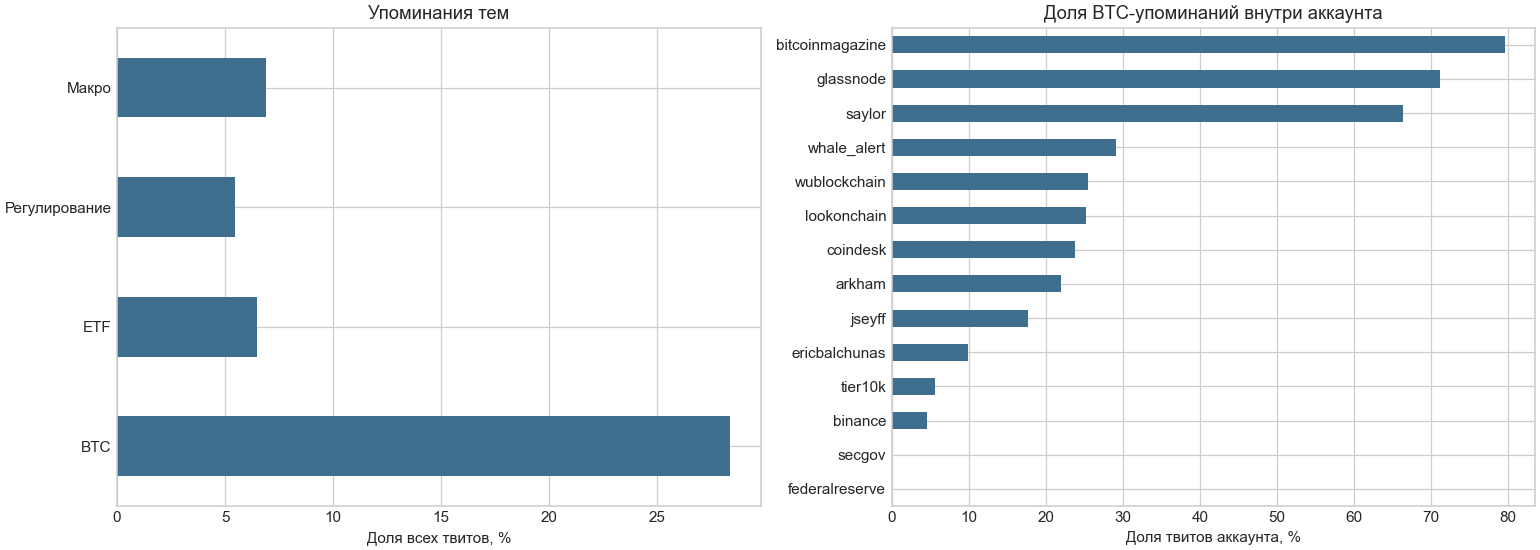

In [10]:
patterns = {
    'BTC': r'\b(?:bitcoin|btc|xbt)\b',
    'ETF': r'\b(?:etfs?|exchange[ -]traded funds?)\b',
    'Регулирование': r'\b(?:sec|cftc|regulat\w*|lawsuits?|enforcement|court|legislation)\b',
    'Макро': r'\b(?:federal reserve|fed|fomc|cpi|inflation|interest rates?|nonfarm|payrolls|treasur(?:y|ies)|gdp)\b'
}
topics = pd.DataFrame({name: text.str.contains(pattern, case=False, regex=True) for name, pattern in patterns.items()})
topic_counts = topics.sum().to_frame('Твитов')
topic_counts['Доля, %'] = 100 * topic_counts['Твитов'] / len(tweets)
display(topic_counts.round(2))
tweets['has_btc'] = topics['BTC']
btc_by_account = tweets.groupby('account')['has_btc'].agg(['sum', 'mean'])
btc_by_account.columns = ['Твитов с BTC', 'Доля BTC, %']
btc_by_account['Доля BTC, %'] *= 100
display(btc_by_account.sort_values('Твитов с BTC', ascending=False).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')
topic_counts['Доля, %'].plot.barh(ax=axes[0], color='#406e8e')
axes[0].set(title='Упоминания тем', xlabel='Доля всех твитов, %', ylabel='')
btc_by_account['Доля BTC, %'].sort_values().plot.barh(ax=axes[1], color='#406e8e')
axes[1].set(title='Доля BTC-упоминаний внутри аккаунта', xlabel='Доля твитов аккаунта, %', ylabel='')
plt.show()

## 10. Частые слова и хештеги

Для слов берём англоязычные твиты без ссылок и RT-префикса. Исключаем служебные английские слова и имена упоминаемых аккаунтов. Считаем число твитов со словом, поэтому повтор слова внутри твита учитывается один раз. Числа исключаем. Хештеги считаем по всей выборке, один хештег внутри твита учитываем один раз.

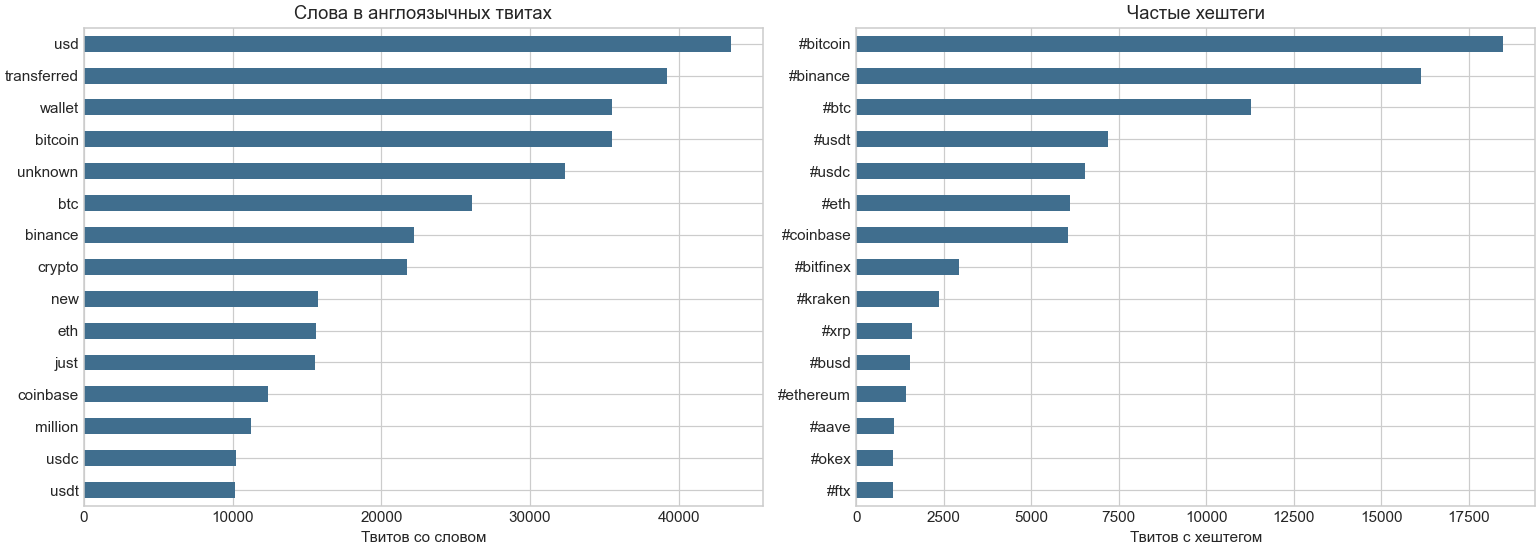

In [11]:
english = normalized.loc[tweets['lang'].eq('en')].str.replace(r'@\w+', ' ', regex=True)
vectorizer = CountVectorizer(stop_words='english', binary=True, max_features=3000,
                             token_pattern=r'(?u)\b[a-z][a-z]{2,}\b')
word_matrix = vectorizer.fit_transform(english)
words = pd.Series(np.asarray(word_matrix.sum(axis=0)).ravel(), index=vectorizer.get_feature_names_out())
words = words.sort_values(ascending=False)
hashtags = text.str.lower().str.findall(r'#\w+').explode().dropna().rename('hashtag').reset_index()
hashtags = hashtags.drop_duplicates(['index', 'hashtag'])['hashtag'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')
words.head(15).sort_values().plot.barh(ax=axes[0], color='#406e8e')
axes[0].set(title='Слова в англоязычных твитах', xlabel='Твитов со словом', ylabel='')
hashtags.head(15).sort_values().plot.barh(ax=axes[1], color='#406e8e')
axes[1].set(title='Частые хештеги', xlabel='Твитов с хештегом', ylabel='')
plt.show()

## 11. Лайки, репосты и просмотры

Счётчики отражают состояние на момент выгрузки. Их поздние значения нельзя напрямую подставлять в исторический прогноз, сделанный при публикации твита. Нулевые просмотры в старых записях могут означать особенности доступности поля. Отдельно показываем долю нулей по годам. На гистограммах только положительные значения.

,count,mean,std,min,50%,90%,99%,max
like_count,200621.0,915.1,7255.2,0.0,123.0,1845.0,10658.0,1047621.0
retweet_count,200621.0,133.4,1056.8,0.0,16.0,284.0,1548.6,206782.0
reply_count,200621.0,110.8,1745.4,0.0,19.0,231.0,1238.8,510241.0
quote_count,200621.0,19.9,407.3,0.0,3.0,33.0,245.0,165359.0
view_count,200621.0,107597.6,1081949.4,0.0,32083.0,207347.0,1072244.8,366655350.0
bookmark_count,200621.0,29.0,359.1,0.0,3.0,37.0,365.0,47467.0


,"Нулей, %",Отрицательных значений
like_count,0.03,0
retweet_count,1.60,0
reply_count,1.21,0
quote_count,20.74,0
view_count,20.27,0
bookmark_count,21.99,0


,"Нулевых просмотров, %"
created_at,
2021,100.00
2022,95.61
2023,0.00
2024,0.00
2025,0.00
2026,0.00


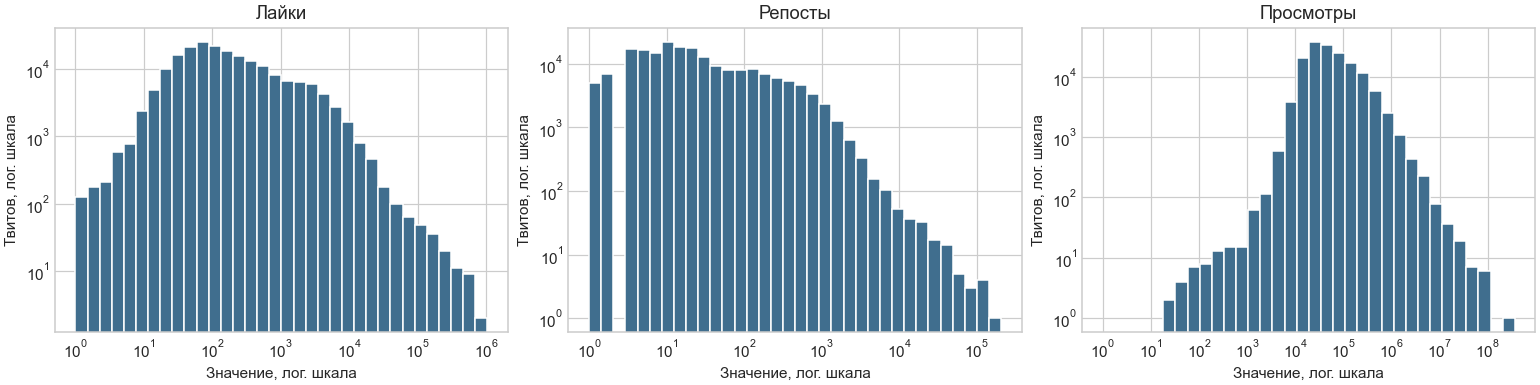

,account,created_at,like_count,text,url
157996,ericbalchunas,2025-09-21 20:19:15+00:00,1047621,RT @elonmusk: Every seat in this giant arena that isn’t roped off for security is packed to the ...,https://x.com/EricBalchunas/status/1969858987832320211
22773,jseyff,2022-06-02 00:57:36+00:00,804625,RT @cartertheepic: Amber Heard will always remember this as the day she almost caught Captain Ja...,https://x.com/JSeyff/status/1532164496420110336
13256,jseyff,2022-02-26 23:14:35+00:00,690604,RT @elonmusk: @FedorovMykhailo Starlink service is now active in Ukraine. More terminals en route.,https://x.com/JSeyff/status/1497711721112293390
42951,ericbalchunas,2023-01-08 01:30:54+00:00,643469,"RT @HamlinIsland: The love is felt, &amp; extremely real. No matter race or religion everybody c...",https://x.com/EricBalchunas/status/1611898204143894528
39773,jseyff,2022-12-09 17:54:05+00:00,632690,RT @nocontextfooty: https://t.co/wXfujDPYUK,https://x.com/JSeyff/status/1601273997894688768


In [12]:
metrics = ['like_count', 'retweet_count', 'reply_count', 'quote_count', 'view_count', 'bookmark_count']
display(tweets[metrics].describe(percentiles=[0.5, 0.9, 0.99]).T.round(1))
display(pd.DataFrame({'Нулей, %': tweets[metrics].eq(0).mean() * 100,
                      'Отрицательных значений': tweets[metrics].lt(0).sum()}).round(2))
zero_views = tweets['view_count'].eq(0).groupby(tweets['created_at'].dt.year).mean().mul(100)
display(zero_views.to_frame('Нулевых просмотров, %').round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), layout='constrained')
for ax, column, title in zip(axes, ['like_count', 'retweet_count', 'view_count'], ['Лайки', 'Репосты', 'Просмотры']):
    values = tweets.loc[tweets[column] > 0, column]
    ax.hist(values, bins=np.geomspace(1, values.max() + 1, 35), color='#406e8e', edgecolor='white')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set(title=title, xlabel='Значение, лог. шкала', ylabel='Твитов, лог. шкала')
plt.show()
display(tweets.nlargest(5, 'like_count')[['account', 'created_at', 'like_count', 'text', 'url']])

## 12. Когда собирались данные

Разница received_at и created_at включает загрузку архива. Она описывает давность сохранённых публикаций и не характеризует задержку оперативного мониторинга.

In [13]:
collection = tweets.groupby(tweets['received_at'].dt.strftime('%Y-%m-%d')).agg(
    tweets=('tweet_id', 'size'), first_saved=('received_at', 'min'), last_saved=('received_at', 'max')
)
display(collection.rename(columns={'tweets': 'Твитов', 'first_saved': 'Начало сохранения UTC',
                                    'last_saved': 'Конец сохранения UTC'}))
lag_days = (tweets['received_at'] - tweets['created_at']).dt.total_seconds() / 86400
display(lag_days.describe(percentiles=[0.1, 0.5, 0.9]).round(1).to_frame('Дней от публикации до сохранения'))

,Твитов,Начало сохранения UTC,Конец сохранения UTC
received_at,,,
2026-10-29,37446,2026-10-29 16:12:53.400040+00:00,2026-10-29 18:38:17.288766+00:00
2026-11-02,163175,2026-11-02 14:50:12.919031+00:00,2026-11-02 21:52:07.276374+00:00


,Дней от публикации до сохранения
count,200621.0
mean,911.9
std,515.3
min,0.0
10%,198.9
50%,925.1
90%,1640.9
max,1825.2


## 13. Новостные окна для часового прогноза

Считаем публикации в окнах [t − окно, t), поэтому сообщения ровно в момент прогноза не включаем. Используем общие часы, для которых все окна лежат внутри полных внутренних дней архива. Отдельно считаем все твиты и твиты с буквальным упоминанием BTC. Ноль означает отсутствие записей в соответствующем окне CSV.

In [14]:
prediction_hours = pd.date_range(first.normalize() + pd.Timedelta(days=1, hours=6), last.normalize(), freq='h')
window_rows = []
for name, selection in [('Все твиты', tweets), ('Упоминания BTC', tweets.loc[tweets['has_btc']])]:
    times = pd.DatetimeIndex(selection['created_at'].sort_values())
    right = times.searchsorted(prediction_hours, side='left')
    for hours in [1, 4, 6]:
        left = times.searchsorted(prediction_hours - pd.Timedelta(hours=hours), side='left')
        counts = pd.Series(right - left)
        window_rows.append({'Выборка': name, 'Окно, ч': hours, 'Медиана твитов': counts.median(),
                            'Среднее твитов': counts.mean(), 'Максимум твитов': counts.max(),
                            'Часов без твитов, %': counts.eq(0).mean() * 100})
windows = pd.DataFrame(window_rows).set_index(['Выборка', 'Окно, ч'])
display(windows.round(2))

Медиана твитов  Среднее твитов  Максимум твитов  \
Выборка        Окно, ч                                                    
Все твиты      1                   4.0            4.58               87   
               4                  15.0           18.32              165   
               6                  23.0           27.47              183   
Упоминания BTC 1                   1.0            1.30               25   
               4                   4.0            5.20               46   
               6                   6.0            7.79               57   

                        Часов без твитов, %  
Выборка        Окно, ч                       
Все твиты      1                       6.77  
               4                       0.05  
               6                       0.03  
Упоминания BTC 1                      39.19  
               4                       7.99  
               6                       3.34

## 14. Выводы

Сводка ниже рассчитывается по текущему файлу. Различия покрытия, шаблонные публикации и накопленные счётчики важно учитывать при подготовке текстовых признаков.

In [15]:
display(Markdown(f'''
- В архиве **{len(tweets):,} уникальных твитов** от **{len(accounts)} аккаунтов**, с **{first:%d.%m.%Y}** по **{last:%d.%m.%Y}**. Повторных tweet_id в исходном файле **{df['tweet_id'].duplicated().sum()}**.
- Два крупнейших источника, **{accounts.index[0]}** и **{accounts.index[1]}**, дают **{accounts['share_pct'].head(2).sum():.1f}%** записей. Состав источников и их покрытие меняются по времени.
- Английский код языка указан у **{tweets['lang'].eq('en').mean():.1%}** твитов. Ретвитов **{tweets['is_retweet'].sum():,}**, цитат **{tweets['is_quote'].sum():,}**, ответов **{tweets['reply_flag'].sum():,}**. Причину отсутствия ответов нужно проверять в настройках сбора.
- Медианная длина — **{tweets['char_count'].median():.0f} символов**, или **{tweets['word_count'].median():.0f} слов**. В повторяющиеся нормализованные шаблоны входят **{int(repeated.sum()):,} твитов**. Разные выпуски дайджестов после удаления ссылок могут совпасть.
- BTC буквально упомянут в **{int(topics['BTC'].sum()):,} твитах ({topics['BTC'].mean():.1%})**. Макроэкономические и регуляторные публикации могут быть релевантны без такого упоминания.
- В часовом окне нет твитов в **{windows.loc[('Все твиты', 1), 'Часов без твитов, %']:.1f}%** моментов. Для BTC-упоминаний эта доля составляет **{windows.loc[('Упоминания BTC', 1), 'Часов без твитов, %']:.1f}%**.
- Лайки, репосты и просмотры накоплены к дате сбора. Для исторической модели нужны значения, известные на момент прогноза, либо признаки только из текста и времени публикации.
- Пустые периоды, нулевые просмотры и отсутствие ответов нельзя автоматически трактовать как реальное отсутствие активности на Twitter.
'''))


- В архиве **200,621 уникальных твитов** от **14 аккаунтов**, с **03.11.2021** по **02.11.2026**. Повторных tweet_id в исходном файле **0**.
- Два крупнейших источника, **whale_alert** и **coindesk**, дают **40.9%** записей. Состав источников и их покрытие меняются по времени.
- Английский код языка указан у **98.3%** твитов. Ретвитов **24,687**, цитат **14,589**, ответов **0**. Причину отсутствия ответов нужно проверять в настройках сбора.
- Медианная длина — **140 символов**, или **22 слов**. В повторяющиеся нормализованные шаблоны входят **12,841 твитов**. Разные выпуски дайджестов после удаления ссылок могут совпасть.
- BTC буквально упомянут в **56,919 твитах (28.4%)**. Макроэкономические и регуляторные публикации могут быть релевантны без такого упоминания.
- В часовом окне нет твитов в **6.8%** моментов. Для BTC-упоминаний эта доля составляет **39.2%**.
- Лайки, репосты и просмотры накоплены к дате сбора. Для исторической модели нужны значения, известные на момент прогноза, либо признаки только из текста и времени публикации.
- Пустые периоды, нулевые просмотры и отсутствие ответов нельзя автоматически трактовать как реальное отсутствие активности на Twitter.
